# Multi-modal Contrastive Analysis (MoCAVI)

Multi-modal Contrastive Analysis (MoCAVI) is a generative model designed to analyze single-cell multi-omics data.
MoCAVI learns to distinguish between a "background" and "target" conditions by integrating information across genes, proteins, and chromatin accessibility. 

MoCAVI is designed to learn two complementary latent spaces:     
    - a "background" latent space that captures variation shared across all cells (e.g., baseline biology like cell cycle, unknown batches),    
    - a "salient" latent space that captures variation unique to a target subset (e.g., perturbations, disease-affected patients) relative to a background subset (e.g., unperturbed cells, unaffected patients).

This tutorial will walk you through setting up, training, and interpreting a MoCAVI model using a single-cell data from a perturbation study with three modalities.

MoCAVI is implemented using scvi-tools.

In [23]:
import numpy as np
import scanpy as sc
import scvi
import seaborn as sns
import pandas as pd

from mocavi import MoCAVIModel

import torch
# make sure cuda is available
print(torch.cuda.is_available())

scvi.settings.seed = 0
print("Last run with scvi-tools version:", scvi.__version__)

Seed set to 0


True
Last run with scvi-tools version: 1.3.0


## Application of MoCAVI to a compound-based screen of CD4+ T-cells

For this case study, we will analyze data from a drug-screening experiment on CD4+ T-cells, generated by the lab of Kelvin Chen at the University of Osaka. Original paper is XXX.

In this study, CD4+ T cells were treated with a panel of kinase inhibitors at three different doses (100 nM, 1 µM, and 10 µM). Each unique combination of a compound and its dose represents a specific treatment condition.

The screen was conducted on primary human and mouse T-cells undergoing T-cell activation, only the human arm of the screen will be used as an example in this tutorial.

The screen was performed across multiple experimental plates. Each plate included wells corresponding to these different treatments, alongside control wells. The controls typically included unstimulated cells (baseline) and stimulated cells treated only with the vehicle (DMSO), serving as the negative control for drug effects under stimulation.

### Setting Up the Data

The dataset used as an example has already been preprocessed. 
Preprocessing steps included: cell assignment to a well and plate, donor annotation, cell and feature filtering, and selection of highly variables genes.
Description of these steps are available in the original publication XXX.

In [ ]:
# let's load the data
out = "data/human_vision.h5ad"
adata = sc.read_h5ad(out)
adata

AnnData object with n_obs × n_vars = 45325 × 5366
    obs: 'Total_UMI', 'Mouse_UMI', 'Human_UMI', 'Percent_Mouse_UMI', 'Percent_Human_UMI', 'Mouse_MT_UMI', 'Human_MT_UMI', 'Percent_Mouse_MT_UMI', 'Percent_Human_MT_UMI', 'Species_Annot_RNA', 'library', 'hto_label', 'ct_label', 'Total_TSB', 'Total_ADT', 'Log_Total_UMI', 'Log_Total_TSB', 'Log_Total_ADT', 'treatment', 'pathway', 'target', 'treatment_alpha', 'n_counts', 'score_s', 'score_g2m', 'donor', 'batch', '_scvi_labels', '_scvi_batch', 'leiden'
    var: 'gene_ids', 'feature_types', 'genome', 'gene_symbols', 'symbols', 'n_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'adt_select_names', 'all_to_remove', 'ct_label_colors', 'donor_colors', 'hto_label_colors', 'hvg', 'leiden', 'leiden_colors', 'library_colors', 'log1p', 'neighbors', 'pathway_colors', 'target_colors', 'totalvi_energy_distance', 'totalvi_energy_distance_null

In this dataset, each cell has been treated with a specific kinase inhibitor at a certain dose, or left untreated as a control.     
Let's explore the main annotations of interest to understand its structure and the various treatment conditions applied.

In [24]:
# get compound and dose from treatment annotation
adata.obs['compound'] = adata.obs['treatment'].str.split('_').str[0]
adata.obs['dose'] = pd.Categorical(adata.obs['treatment'].str.split('_').str[1], 
                                categories=['100nM', '1uM', '10uM'], ordered=True)

In [87]:
# assign control_other category based on compound
def assign_control_other(compound):
    if compound not in ["Vehicle", "No stim"]:
        return "other"
    else:
        return compound
    
adata.obs['control_other'] = adata.obs['compound'].apply(assign_control_other).astype('category')

In [30]:
adata.obs['compound'].value_counts().head(10)

compound
No stim          2067
Refametinib      1439
Vehicle          1392
Ridaforolimus    1391
Everolimus       1379
GSK690693        1246
Selumetinib      1105
ASP4132          1007
MK-3903           975
Solcitinib        929
Name: count, dtype: int64

In [37]:
adata.obs['treatment'].value_counts().head(10)

treatment
No stim_10uM_H           782
No stim_100nM_H          679
Refametinib_10uM_H       671
No stim_1uM_H            606
GSK690693_10uM_H         587
Vehicle_10uM_H           538
Selumetinib_10uM_H       525
Everolimus_10uM_H        510
Ridaforolimus_10uM_H     505
Ridaforolimus_100nM_H    472
Name: count, dtype: int64

In [59]:
print(adata.obs[['compound', 'library', 'dose']].value_counts())
adata[adata.obs['compound'].isin(['Flavopiridol'])].obs[['library', 'dose']].value_counts()
#adata[adata.obs['compound'].isin(['Tozasertib'])].obs[['dose']].value_counts()

compound              library  dose 
No stim               H        10uM     204
                      D        10uM     203
Refametinib           D        10uM     194
No stim               E        10uM     191
                      D        100nM    189
                                       ... 
Tozasertib            G        1uM        6
Pitavastatin Calcium  F        10uM       5
AZD1480               G        10uM       4
OSU-03012             G        10uM       3
Tozasertib            F        1uM        3
Name: count, Length: 855, dtype: int64


library  dose 
H        100nM    47
E        100nM    44
D        100nM    40
F        100nM    17
G        100nM    16
Name: count, dtype: int64

In [33]:
# Get unique counts for each column of interest
unique_counts = adata.obs[['library', 'batch',
                           'compound', 'dose', 'treatment',
                           'pathway', 'target']].nunique()

print("Unique number of levels per annotation:")
print(unique_counts)

Unique number of levels per annotation:
library        5
batch         10
compound      58
dose           3
treatment    171
pathway       11
target        48
dtype: int64


Without counting the Vehicle and No Stim controls, there are 56 kinase inhibitors and 171 treatments. Three compound:dose combinations have been excluded during preprocessing as there were not enough cells remaining for analysis. 
We recommend discarding treatments with not enough cells. Here, we kept treatments with at least 45 (XXX @Romain) cells to be able to accurately estimate their distribution in the salient latent space.

### Assigning cells to target vs baseline

There are various ways one can decide which cells belong to the target condition.
Here, we will consider as target cells those that were treated with a pre-selected set of drugs for which we saw an effect compared to the Vehicle cells in a preliminary analysis.
Although untreated, unstimulated cells are also included in the target condition as they are biologically distinct from the global cell population.
All other cells, including the Vehicle cells, will only be used to estimate the background environment and not the salient one.

We recommend having at least XXX (@Romain 20%?) of cells assigned to the baseline environment.

XXX @Romain do we want to show how treatments were selected? I assumed out-of-scope for now.

In [38]:
# specify the baseline environment and the target environments
all_to_remove = adata.uns["all_to_remove"]
background_dataset = np.logical_or(
    adata.obs["compound"] == "Vehicle", np.array([x in all_to_remove for x in adata.obs["treatment"]])
)
background_indices = np.where(background_dataset)[0]
target_indices = np.where(~background_dataset)[0]

print(f"{len(target_indices)} out of {adata.n_obs} cells will be used as target cells.")
print(f"{(adata.obs['treatment'].iloc[target_indices].nunique())} out of {adata.obs['treatment'].nunique()} treatments will be used to estimate the salient latent space.")

11161 out of 45325 cells will be used as target cells.
34 out of 171 treatments will be used to estimate the salient latent space.


`background_indices` and `target_indices` contain the indices of the cells assigned to each environment, respectively. They will be used during the VAE training.

### Load AnnData object into MoCAVI and instantiate the model

MoCAVI needs to know where to find each data type, as well as the batch and condition labels for each cell. 
We provide this information using the `MoCAVIModel.setup_anndata` method.

For this model, the data should be structured as follows:
* RNA-seq & ATAC-seq (concatenated): MoCAVI is designed to receive gene expression and chromatin accessibility counts as a single, concatenated matrix. This matrix should be stored in a specified location, like adata.layers["counts"]. The model is then told how to split this matrix internally using the `n_genes` and `n_regions` parameters during initialization. If no chromatin accessibility counts is available, `n_regions` should be set to zero.   
counts[:, :n_genes] will be treated as RNA. 
counts[:, n_genes : n_genes + n_regions] will be treated as ATAC.   
* ADT (Protein): Raw protein counts are stored separately in adata.obsm (e.g., adata.obsm["adt_counts"]), with the corresponding protein names in adata.uns (here `adata.obsm['adt_select']`). 
* Metadata (adata.obs): The observation-level metadata must include columns for:
    * the batch annotation  
    * the label of each target condition of interest    

In [71]:
# register RNA + ADT + ATAC (regions) if present
MoCAVIModel.setup_anndata(
    adata,
    batch_key="batch",
    labels_key="treatment",
    layer="counts",
    protein_expression_obsm_key="adt_select",
    protein_names_uns_key="adt_select_names",
)


INFO     Using column names from adata.uns['adt_select_names']                                                     


In [72]:
model = MoCAVIModel(
    adata,
    n_genes=adata.n_vars,
    n_regions=0, # in this example we don't have ATAC-Seq data
    n_salient_latent=15,
    n_background_latent=10,
    n_layers_decoder=2,
    reweighting_mode="auto",
)

It is recommended to review the setup to ensure it is correct

In [73]:
model.view_anndata_setup()

Anndata setup with scvi-tools version 1.3.0.

Setup via `MoCAVIModel.setup_anndata` with arguments:

{
│   'protein_expression_obsm_key': 'adt_select',
│   'protein_names_uns_key': 'adt_select_names',
│   'layer': 'counts',
│   'batch_key': 'batch',
│   'labels_key': 'treatment',
│   'categorical_covariate_keys': None,
│   'continuous_covariate_keys': None
}

         Summary Statistics         
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃     Summary Stat Key     ┃ Value ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│         n_batch          │  10   │
│         n_cells          │ 45325 │
│ n_extra_categorical_covs │   0   │
│ n_extra_continuous_covs  │   0   │
│         n_labels         │  171  │
│        n_proteins        │  83   │
│          n_vars          │ 5366  │
└──────────────────────────┴───────┘

               Data Registry                
┏━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Registry Key ┃    scvi-tools Location    ┃
┡━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│      X       │  adata.layers['counts']   │
│    batch     │ adata.obs['_scvi_batch']  │
│    labels    │ adata.obs['_scvi_labels'] │
│   proteins   │ adata.obsm['adt_select']  │
└──────────────┴───────────────────────────┘

                  batch State Registry                   
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃  Source Location   ┃ Categories ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['batch'] │     D0     │          0          │
│                    │     D1     │          1          │
│                    │     E0     │          2          │
│                    │     E1     │          3          │
│                    │     F0     │          4          │
│                    │     F1     │          5          │
│                    │     G0     │          6          │
│                    │     G1     │          7          │
│                    │     H0     │          8          │
│                    │     H1     │          9          │
└────────────────────┴────────────┴─────────────────────┘

                             labels State Registry                             
┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃    Source Location     ┃          Categories          ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['treatment'] │      8-Bromo-cAMP_1uM_H      │          0          │
│                        │     8-Bromo-cAMP_10uM_H      │          1          │
│                        │     8-Bromo-cAMP_100nM_H     │          2          │
│                        │       AS1517499_1uM_H        │          3          │
│                        │       AS1517499_10uM_H       │          4          │
│                        │      AS1517499_100nM_H       │          5          │
│                        │        ASP4132_1uM_H         │          6          │
│                        │        ASP4132_10uM_H        │          7          │
│                        │       ASP4132_100nM_H        │          8          │
│                        │        AZD1480_1uM_H         │          9          │
│                        │        AZD1480_10uM_H        │         10          │
│                        │       AZD1480_100nM_H        │         11          │
│                        │     Acetylcysteine_1uM_H     │         12          │
│                        │    Acetylcysteine_10uM_H     │         13          │
│                        │    Acetylcysteine_100nM_H    │         14          │
│                        │       Amuvatinib_1uM_H       │         15          │
│                        │      Amuvatinib_10uM_H       │         16          │
│                        │      Amuvatinib_100nM_H      │         17          │
│                        │        Axitinib_1uM_H        │         18          │
│                        │       Axitinib_10uM_H        │         19          │
│                        │       Axitinib_100nM_H       │         20          │
│                        │         BX-795_1uM_H         │         21          │
│                        │        BX-795_10uM_H         │         22          │
│                        │        BX-795_100nM_H        │         23          │
│                        │     Benidipine HCl_1uM_H     │         24          │
│                        │    Benidipine HCl_10uM_H     │         25          │
│                        │    Benidipine HCl_100nM_H    │         26          │
│                        │  Cabozantinib malate_1uM_H   │         27          │
│                        │  Cabozantinib malate_10uM_H  │         28          │
│                        │ Cabozantinib malate_100nM_H  │         29          │
│                        │      Cabozantinib_1uM_H      │         30          │
│                        │     Cabozantinib_10uM_H      │         31          │
│                        │     Cabozantinib_100nM_H     │         32          │
│                        │       Crizotinib_1uM_H       │         33          │
│                        │      Crizotinib_10uM_H       │         34          │
│                        │      Crizotinib_100nM_H      │         35          │
│                        │       Dasatinib_1uM_H        │         36          │
│                        │       Dasatinib_10uM_H       │         37          │
│                        │      Dasatinib_100nM_H       │         38          │
│                        │      Doramapimod_1uM_H       │         39          │
│                        │      Doramapimod_10uM_H      │         40          │
│                        │     Doramapimod_100nM_H      │         41          │
│                        │       Dovitinib_1uM_H        │         42          │
│                        │       Dovitinib_10uM_H       │         43          │
│                        │      Dovitinib_100nM_H       │         44          │
│                        │       ERK5-IN-1_1uM_H        │         45          │


### Train the MoCAVI model

In [74]:
train = True #set to False to load a pre-trained model
save_dir = "data/model"

In [75]:
if train:
# train the model
    model.train(
        max_epochs=75,
        background_indices=background_indices,
        target_indices=target_indices,
        check_val_every_n_epoch=1,
        early_stopping=True,
        plan_kwargs={
            "n_epochs_kl_warmup": 50,
        },
    )
else:
    model = MoCAVIModel.load(save_dir, adata)

/gpfs/scratchfs01/site/u/bitona1/pixi/mocavi2/.pixi/envs/default/lib/python3.10/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /gpfs/scratchfs01/site/u/bitona1/pixi/mocavi2/.pixi/ ...
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/gpfs/scratchfs01/site/u/bitona1/pixi/mocavi2/.pixi/envs/default/lib/python3.10/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /gpfs/scratchfs01/site/u/bitona1/pixi/mocavi2/.pixi/ ...
/gpfs/scratchfs01/site/u/bitona1/pixi/mocavi2/.pixi/envs/default/lib/python3.10/site-packages/torch/__init__.py:1551: Us

Epoch 1/75:   0%|          | 0/75 [00:00<?, ?it/s]

/gpfs/scratchfs01/site/u/bitona1/pixi/mocavi2/.pixi/envs/default/lib/python3.10/site-packages/lightning/pytorch/utilities/data.py:79: Trying to infer the `batch_size` from an ambiguous collection. The batch size we found is 128. To avoid any miscalculations, use `self.log(..., batch_size=batch_size)`.


Epoch 2/75:   1%|▏         | 1/75 [00:07<09:20,  7.58s/it, v_num=1, train_loss_step=3.44e+3, train_loss_epoch=3.77e+3]

/gpfs/scratchfs01/site/u/bitona1/pixi/mocavi2/.pixi/envs/default/lib/python3.10/site-packages/lightning/pytorch/utilities/data.py:79: Trying to infer the `batch_size` from an ambiguous collection. The batch size we found is 88. To avoid any miscalculations, use `self.log(..., batch_size=batch_size)`.


Epoch 75/75: 100%|██████████| 75/75 [07:22<00:00,  5.86s/it, v_num=1, train_loss_step=3.34e+3, train_loss_epoch=3.22e+3]

`Trainer.fit` stopped: `max_epochs=75` reached.


Epoch 75/75: 100%|██████████| 75/75 [07:22<00:00,  5.89s/it, v_num=1, train_loss_step=3.34e+3, train_loss_epoch=3.22e+3]


After running model.train(), the training history is stored in model.history.   
Plotting the negative ELBO (the optimized objective; lower is better) and the KL term(s) helps you verify that learning behaved as expected.

* Total loss (−ELBO / validation loss): This is the primary metric the model optimizes. You want to see both curves decrease steadily and then plateau. 
If the validation loss starts increasing while training loss keeps decreasing, it indicates overfitting (consider early stopping at the minimum validation epoch).  
* KL term(s): Early on, the KL often grows from ~0 as the latent space organizes, then stabilizes.

In [76]:
model.history.keys()

dict_keys(['kl_weight', 'train_loss_step', 'validation_loss', 'elbo_validation', 'reconstruction_loss_validation', 'kl_local_validation', 'kl_global_validation', 'wasserstein_loss_sum_validation', 'train_loss_epoch', 'elbo_train', 'reconstruction_loss_train', 'kl_local_train', 'kl_global_train', 'wasserstein_loss_sum_train'])

<Axes: xlabel='epoch'>

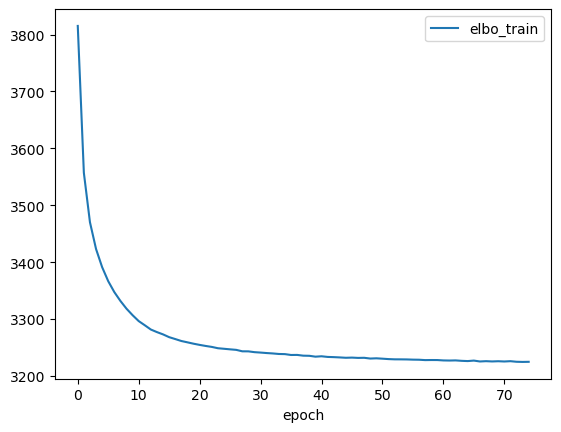

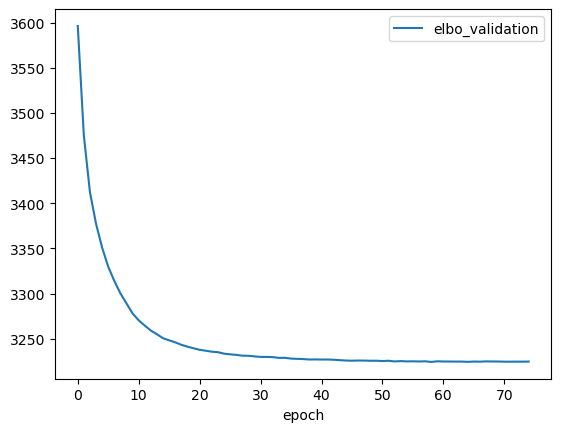

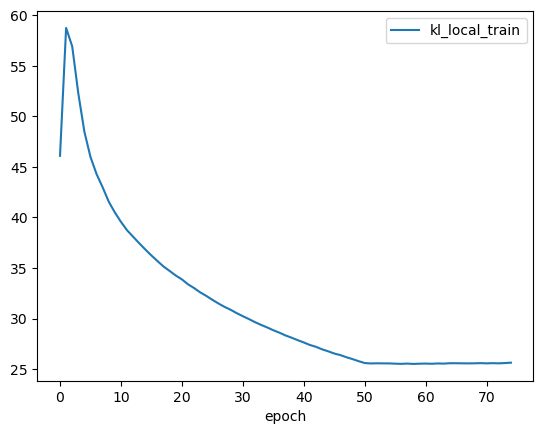

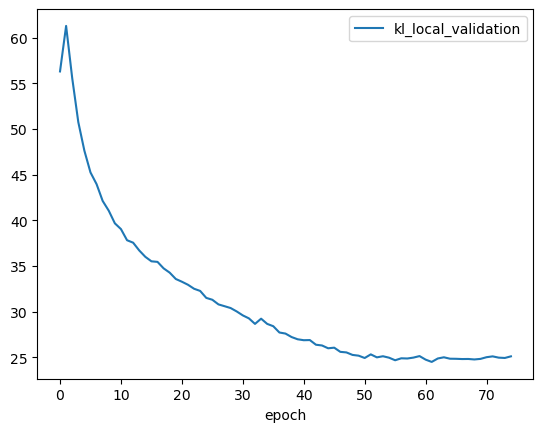

In [101]:
import matplotlib.pyplot as plt

model.history["elbo_train"].plot(label="Train (−ELBO)")
model.history["elbo_validation"].plot(label="Validation (−ELBO)")
model.history["kl_local_train"].plot(label="Train KL Local")
model.history["kl_local_validation"].plot(label="Validation KL Local")

### Extract and plot the distribution of the cells in the background and salient latent spaces

In [78]:
# get salient latent space
adata.obsm["salient_rep"] = model.get_latent_representation(adata, representation_kind="salient")
# umap of salient latent space
sc.pp.neighbors(adata, use_rep="salient_rep")
sc.tl.umap(adata)
adata.obsm["X_salient_umap"] = adata.obsm["X_umap"].copy()

In [79]:
adata.obs.columns

Index(['Total_UMI', 'Mouse_UMI', 'Human_UMI', 'Percent_Mouse_UMI',
       'Percent_Human_UMI', 'Mouse_MT_UMI', 'Human_MT_UMI',
       'Percent_Mouse_MT_UMI', 'Percent_Human_MT_UMI', 'Species_Annot_RNA',
       'library', 'hto_label', 'ct_label', 'Total_TSB', 'Total_ADT',
       'Log_Total_UMI', 'Log_Total_TSB', 'Log_Total_ADT', 'treatment',
       'pathway', 'target', 'treatment_alpha', 'n_counts', 'score_s',
       'score_g2m', 'donor', 'batch', '_scvi_labels', '_scvi_batch', 'leiden',
       'compound', 'dose'],
      dtype='object')

In [85]:
adata.obs[['dose', 'hto_label']].value_counts()

dose   hto_label
10uM   10uM_H       16353
1uM    1uM_H        14701
100nM  100nM_H      14271
Name: count, dtype: int64

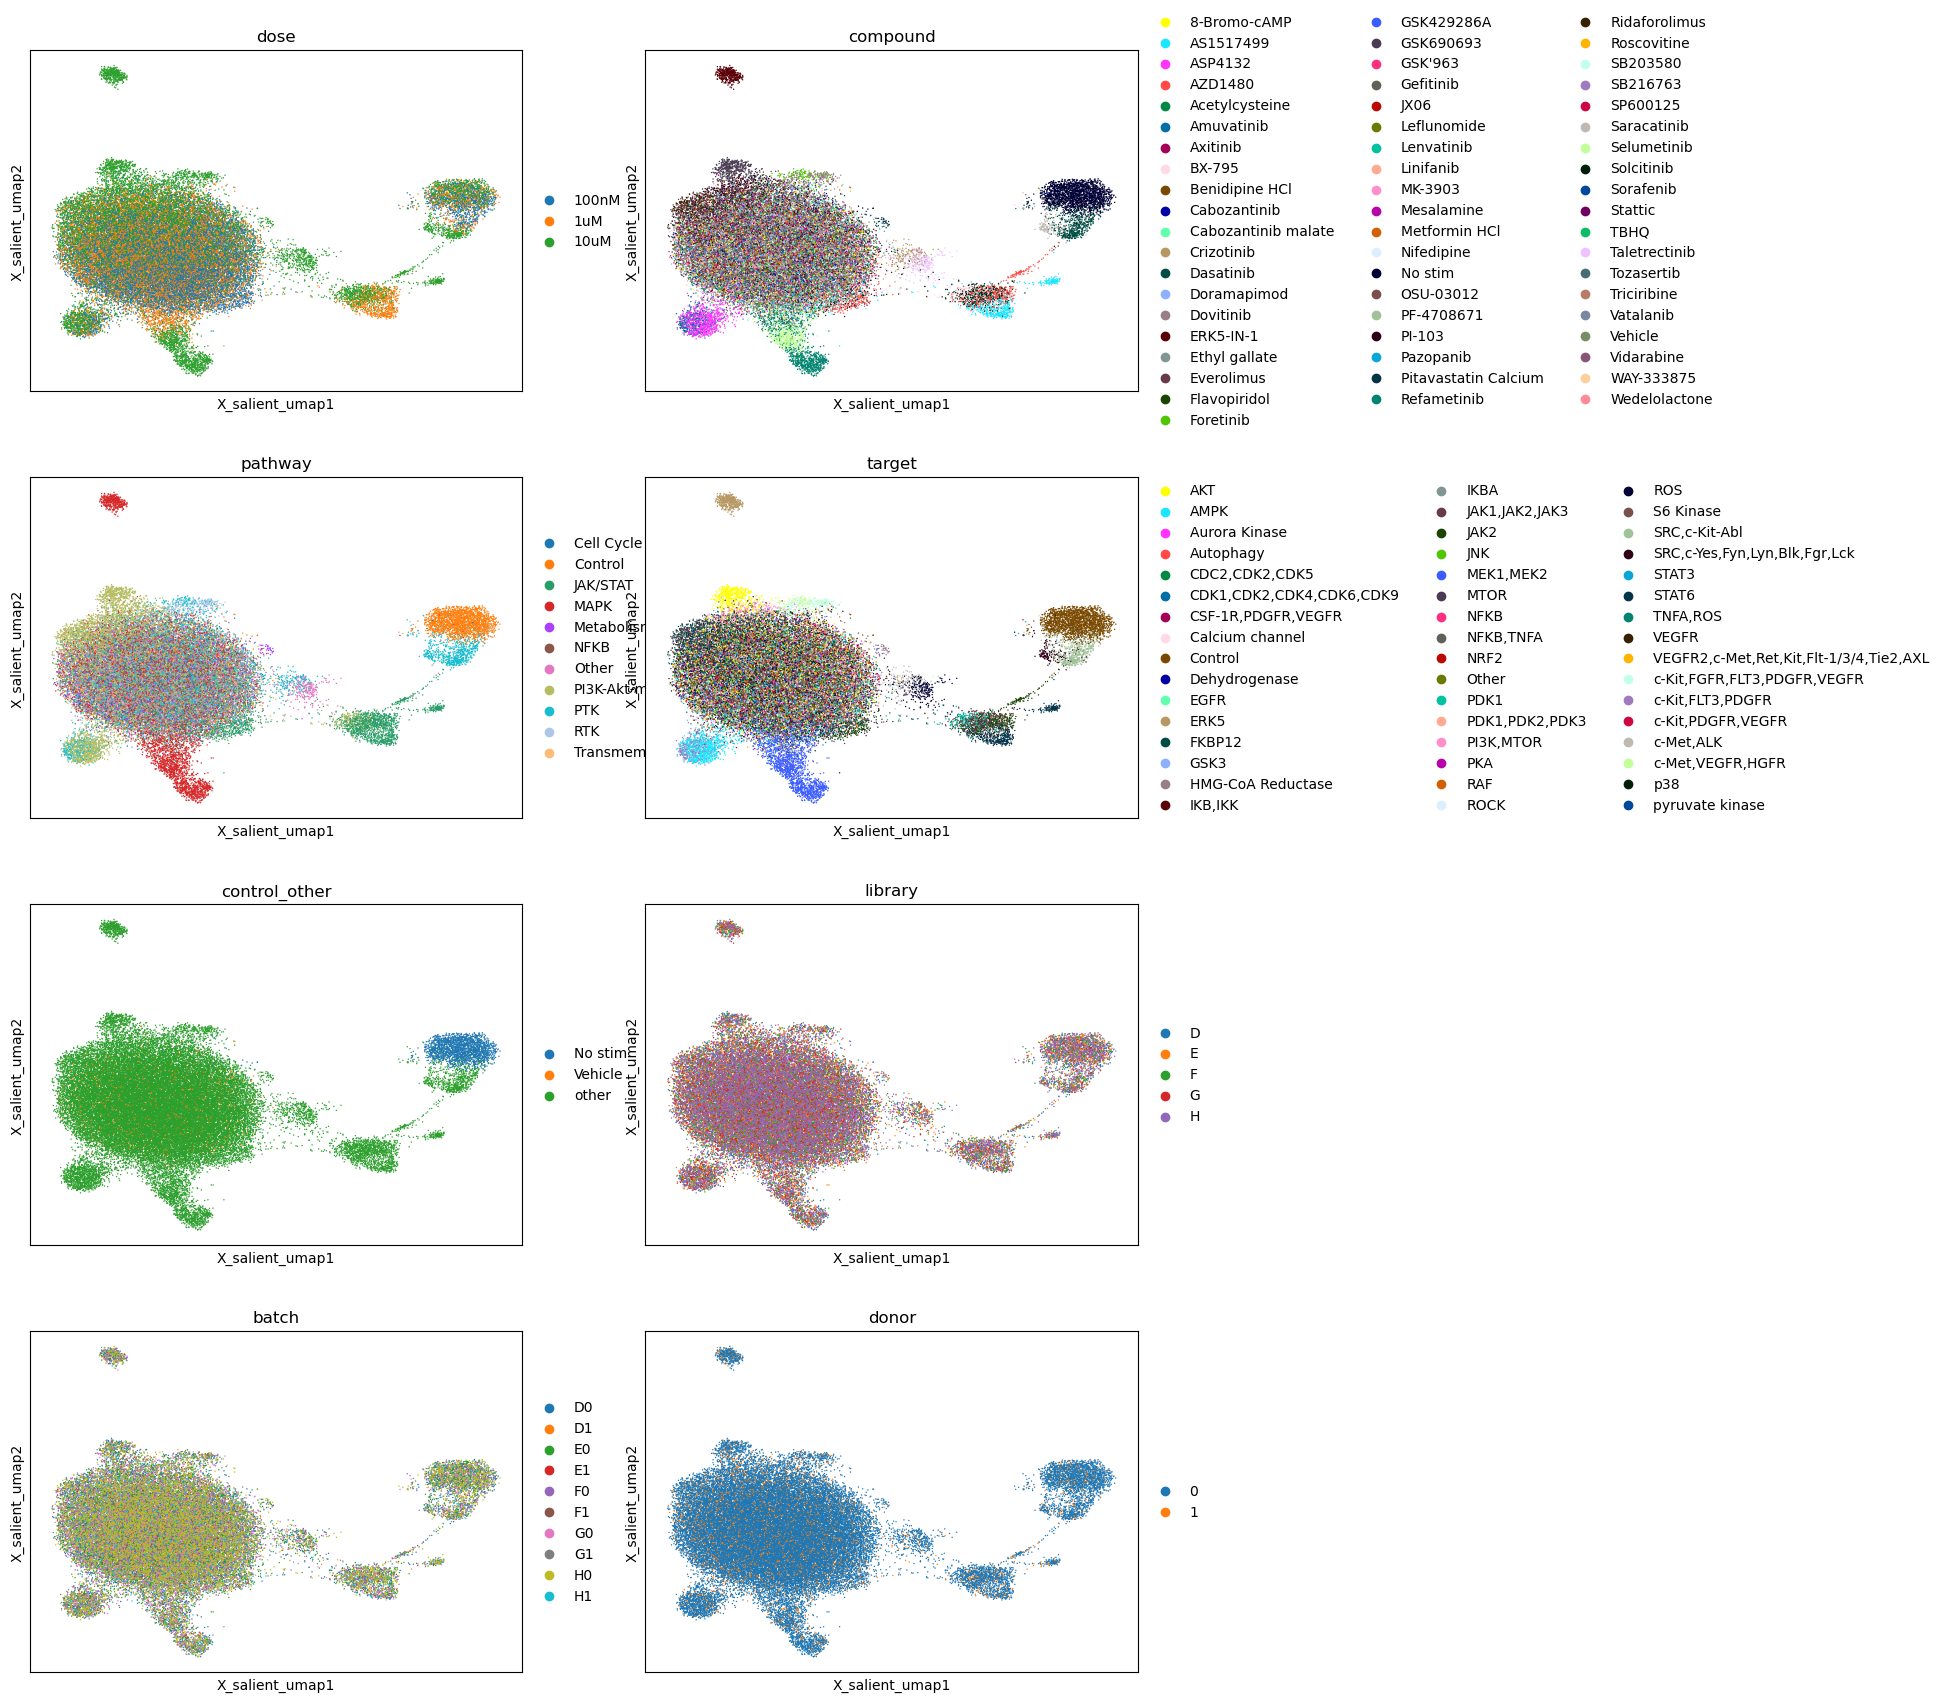

In [92]:
# quick glance at the salient latent space
sc.pl.embedding(
    adata,
    basis="X_salient_umap",
    color=["dose", "compound", "pathway", "target", "control_other", "library", "batch", "donor"],
    ncols=2,
    size=4,
)

In [89]:
# get background latent space
adata.obsm["background_rep"] = model.get_latent_representation(adata, representation_kind="background")
# umap of background latent space
sc.pp.neighbors(adata, use_rep="background_rep")
sc.tl.umap(adata)
adata.obsm["X_background_umap"] = adata.obsm["X_umap"].copy()

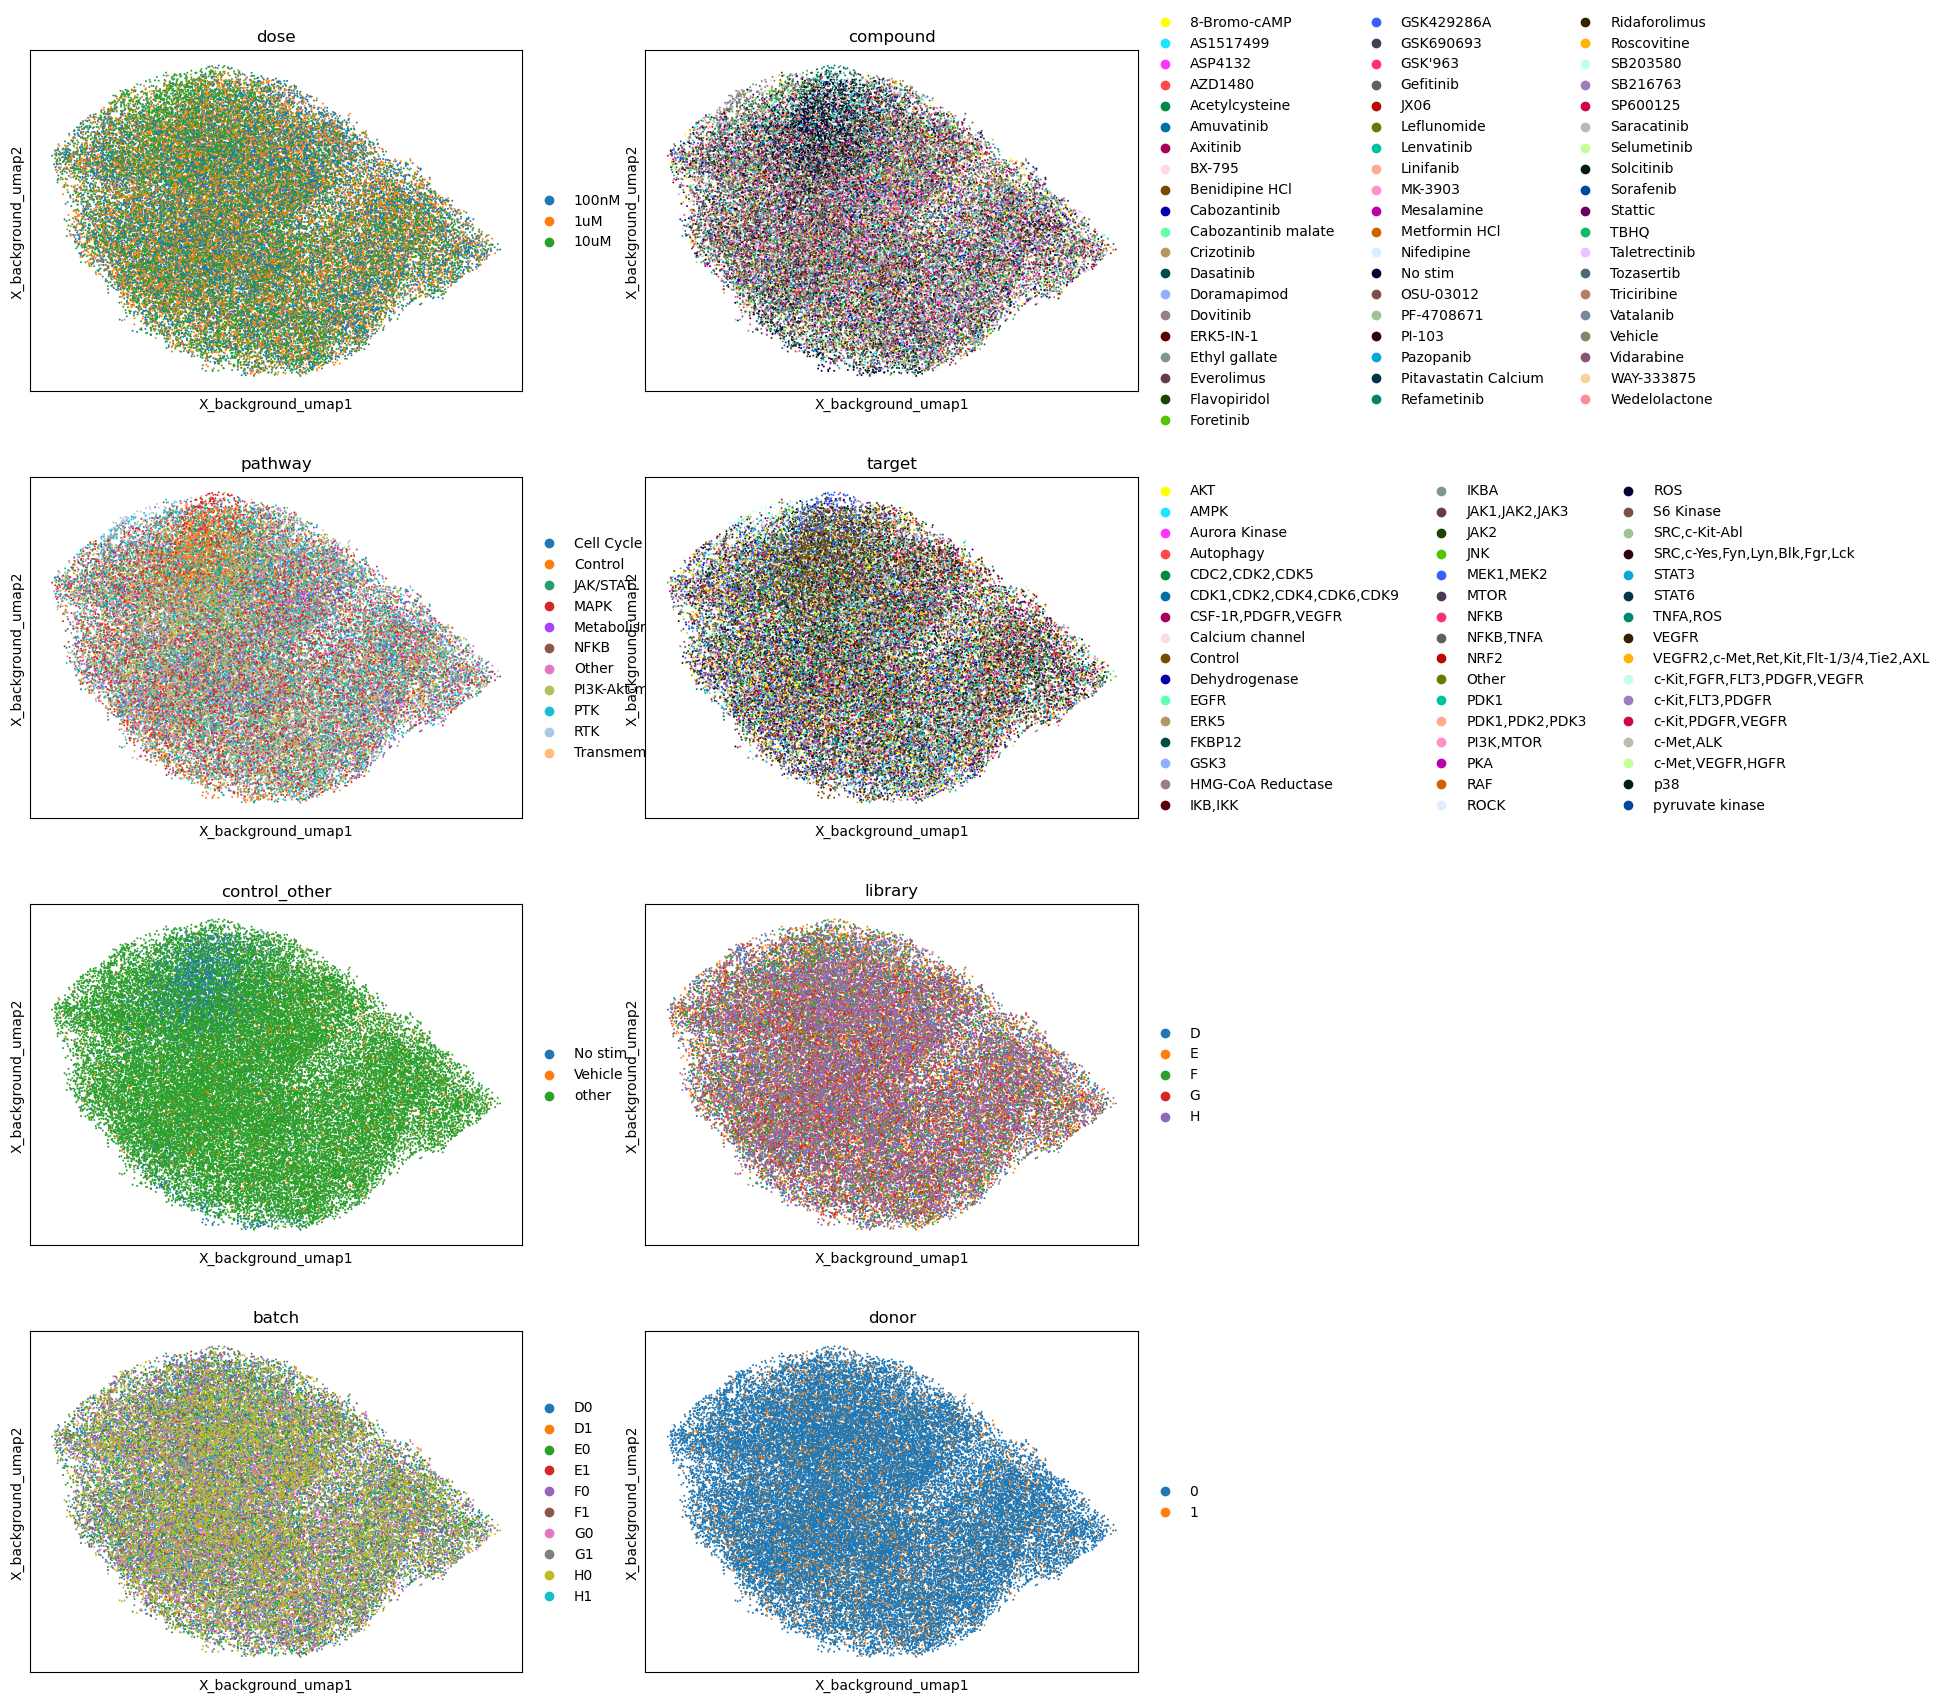

In [94]:
# quick glance at the background latent space
sc.pl.embedding(
    adata,
    basis="X_background_umap",
    color=["dose", "compound", "pathway", "target", "control_other", "library", "batch", "donor"],
    ncols=2,
    size=8,
)

Is the global cell cycle activity captured in the background or salient space? 
It should be captured in the background space, which allows to focus on proliferation patterns specific to treatment in the salient space, if any.

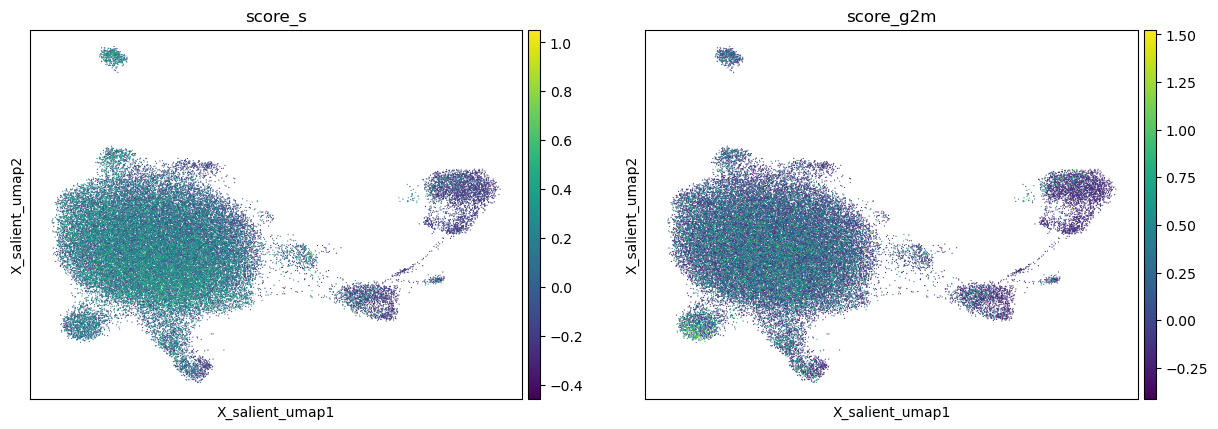

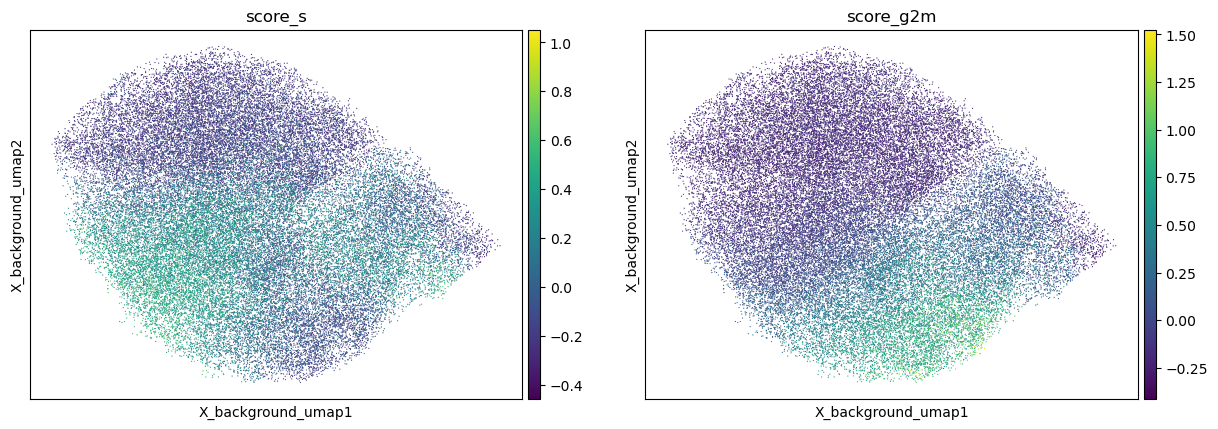

In [95]:
sc.pl.embedding(
    adata,
    basis="X_salient_umap",
    color=["score_s", "score_g2m"],
    ncols=2,
    size=3
)

sc.pl.embedding(
    adata,
    basis="X_background_umap",
    color=["score_s", "score_g2m"],
    ncols=2,
    size=3
)

### Salient-specific log fold change estimation

In [96]:
# perform synthetic differential abundance on selected conditions
conditions_of_interest = [
    "OSU-03012_1uM_H",
    "GSK690693_10uM_H",
    "GSK690693_1uM_H",
    "Stattic_10uM_H",
    "Dovitinib_10uM_H",
    "Saracatinib_1uM_H",
    "Tozasertib_10uM_H",
    "OSU-03012_10uM_H",
    "Foretinib_10uM_H",
    "Ridaforolimus_100nM_H",
    "Ridaforolimus_1uM_H",
    "Everolimus_10uM_H",
    "Ridaforolimus_10uM_H",
    "Everolimus_1uM_H",
    "PI-103_10uM_H",
    "PI-103_1uM_H",
    "Everolimus_100nM_H",
    "Saracatinib_10uM_H",
    "No stim_10uM_H",
    "Dasatinib_10uM_H",
    "No stim_1uM_H",
    "No stim_100nM_H",
    "Dasatinib_100nM_H",
    "Dasatinib_1uM_H",
    "Selumetinib_1uM_H",
    "Refametinib_1uM_H",
    "Refametinib_10uM_H",
    "Refametinib_100nM_H",
    "Selumetinib_10uM_H",
    "PF-4708671_10uM_H",
    "Solcitinib_10uM_H",
    "AS1517499_10uM_H",
    "AS1517499_1uM_H",
    "AZD1480_1uM_H",
    "BX-795_10uM_H",
    "AZD1480_10uM_H",
    "AZD1480_100nM_H",
    "Taletrectinib_10uM_H",
    "Solcitinib_1uM_H",
    "Crizotinib_10uM_H",
    "AS1517499_100nM_H",
    "ERK5-IN-1_10uM_H",
    "Pitavastatin Calcium_10uM_H",
    "Flavopiridol_100nM_H",
    "ERK5-IN-1_1uM_H",
    "ASP4132_1uM_H",
    "ASP4132_100nM_H",
    "ASP4132_10uM_H",
    "Amuvatinib_10uM_H",
]
modality_key = "exp"
res = model.synthetic_differential_abundance(
    groupby="treatment", group1=conditions_of_interest, modality_key=modality_key
)
res["feature"] = res.index.values

DE...:   0%|          | 0/49 [00:00<?, ?it/s]

DE...: 100%|██████████| 49/49 [01:27<00:00,  1.78s/it]


In [97]:
lfc_treatment = res.pivot(index="group1", columns="feature", values="lfc_median")

/gpfs/scratchfs01/site/u/bitona1/pixi/mocavi2/.pixi/envs/default/lib/python3.10/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/gpfs/scratchfs01/site/u/bitona1/pixi/mocavi2/.pixi/envs/default/lib/python3.10/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


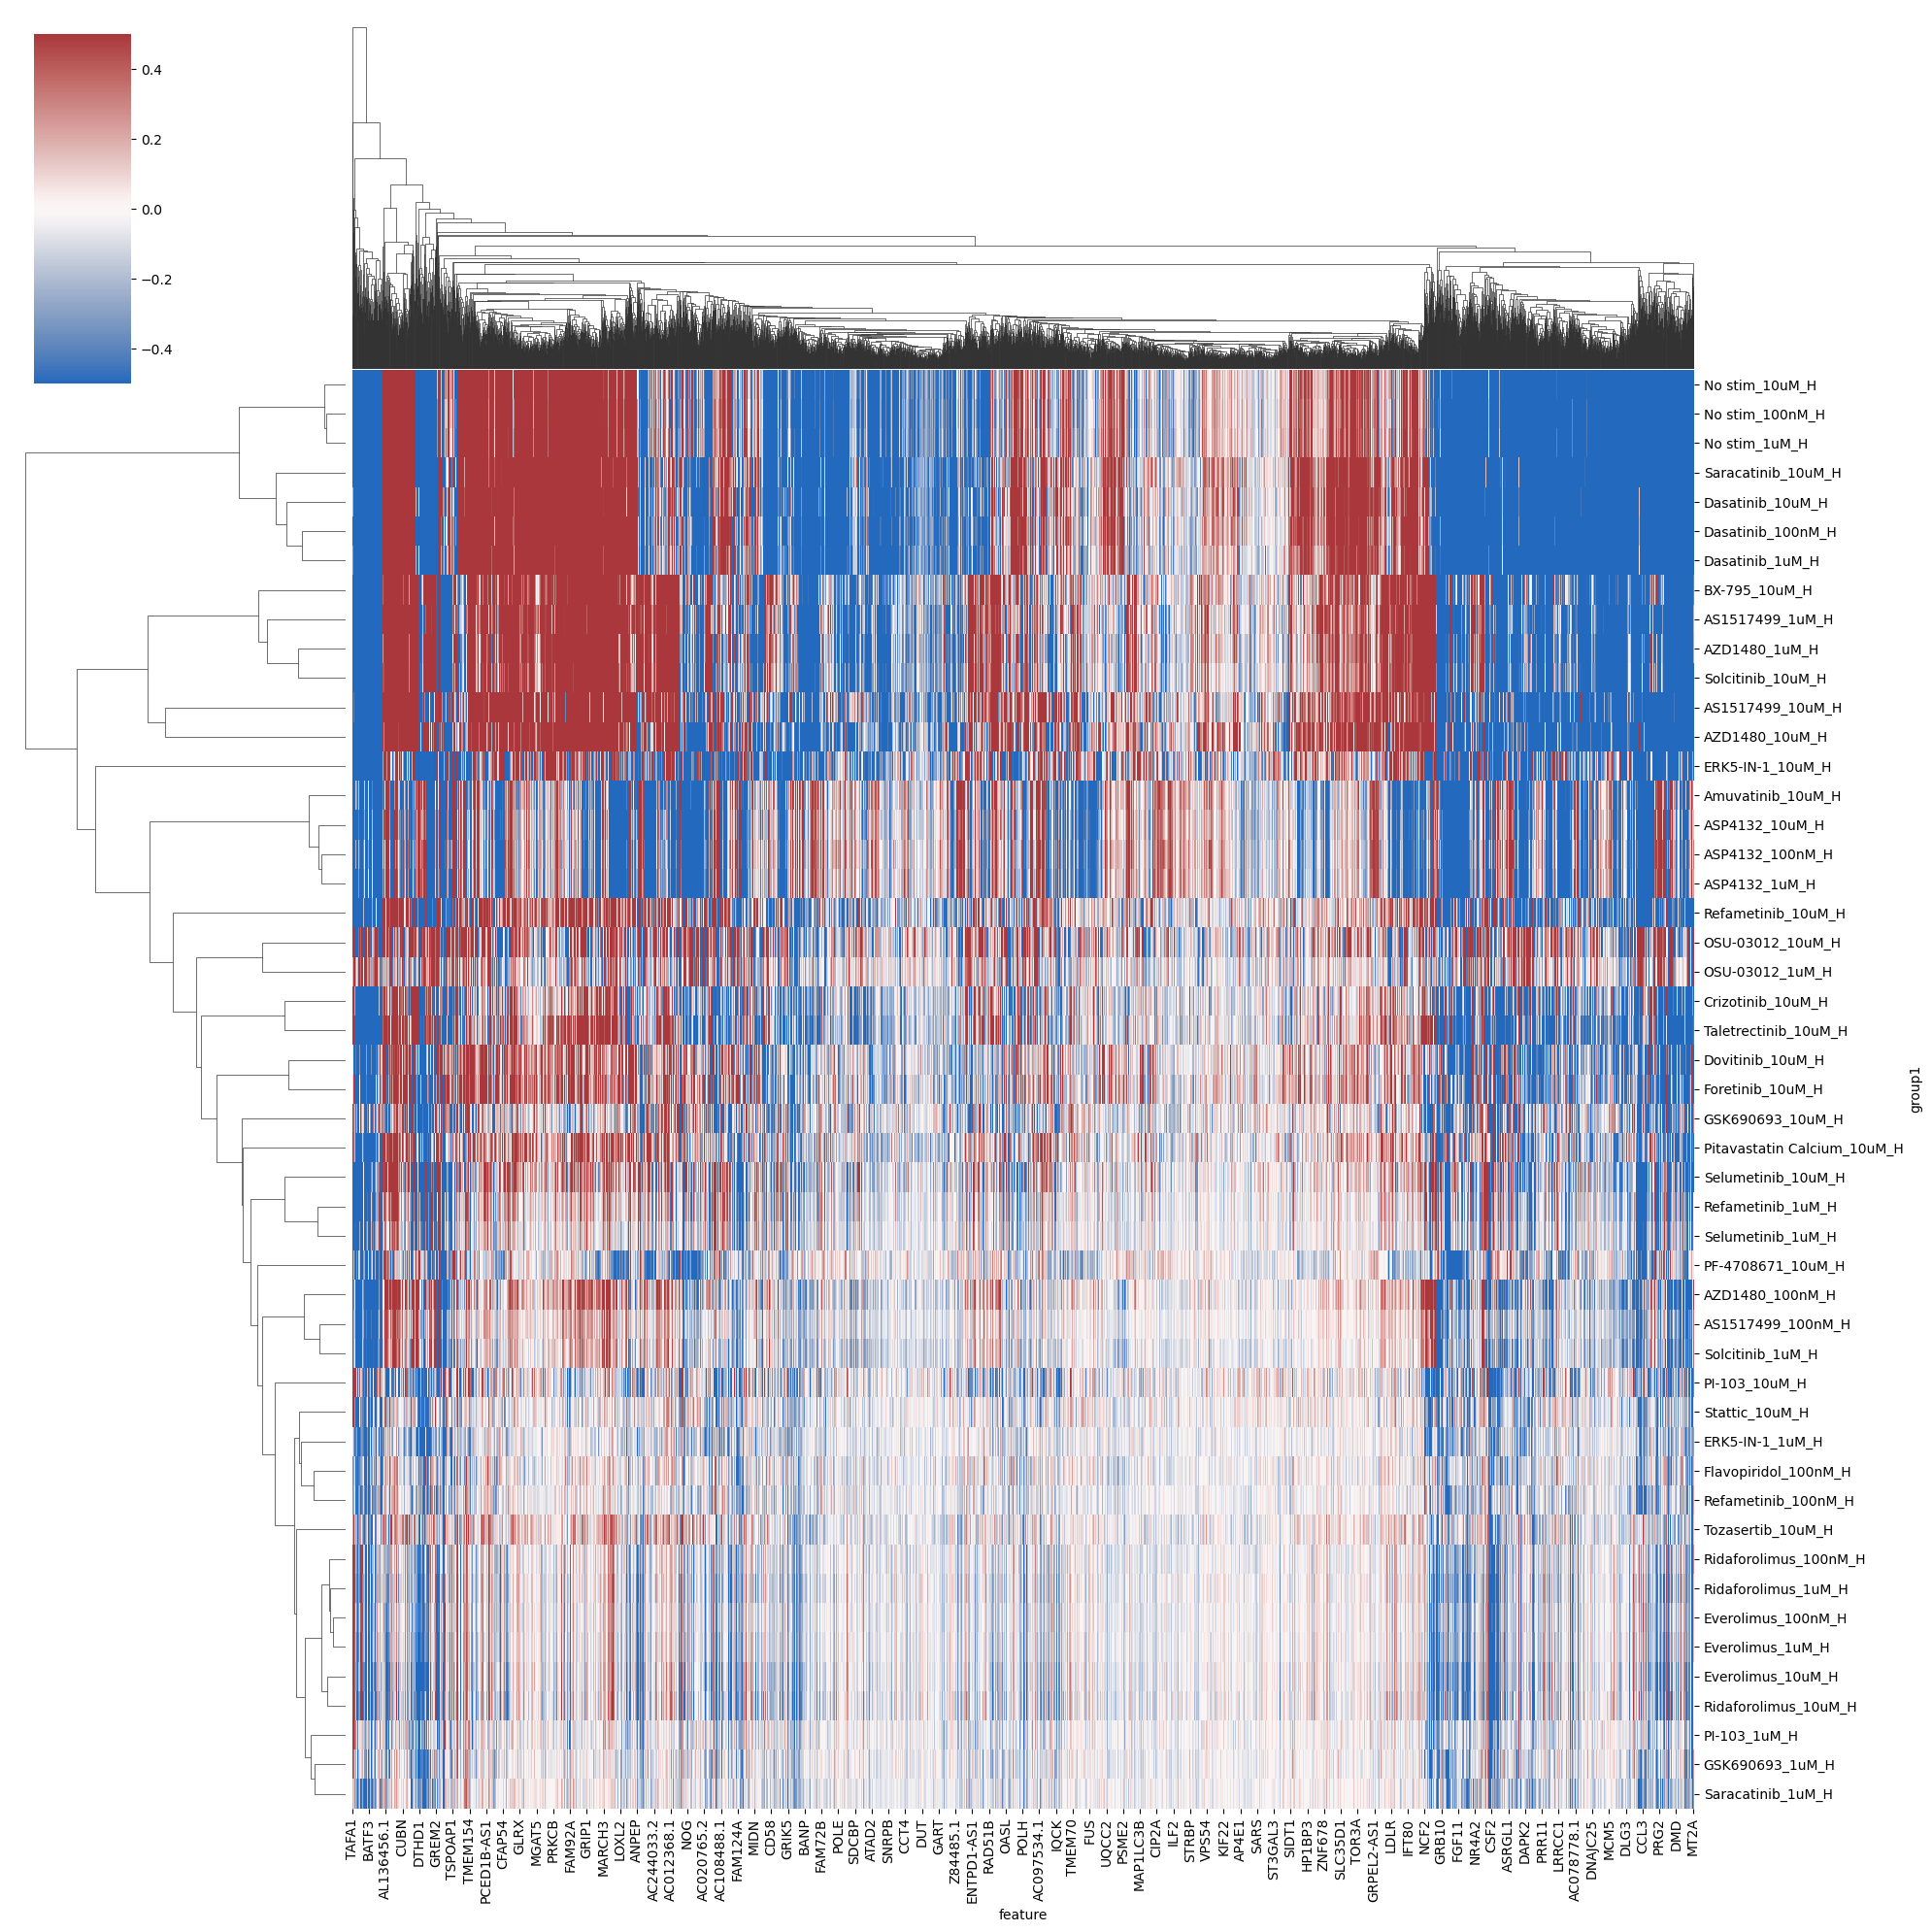

In [98]:
sns.clustermap(lfc_treatment, cmap="vlag", center=0, vmax=0.5, vmin=-0.5, figsize=(20, 20))